# 04 · Barangay check: does flood hazard point to where cases are?

**Goal:** the app ranks Iloilo barangays by *flood hazard × population*. Iloilo has no
barangay case data, so we test the idea in **Zamboanga City**, the only city with usable
barangay-level leptospirosis records (2013–2022, see notebook 01).

In [1]:
from scipy.stats import spearmanr

from common import *

style()

lgu = pd.read_csv(RAW / "disease_lgu_disaggregated_totals.csv", parse_dates=["date"])
z = lgu[(lgu.disease_common_name == "LEPTOSPIROSIS") & (lgu.source_filename == "Zamboanga_PIDSR_2013-2022")]
city_total = lepto_weekly().query("city == @ZAMBOANGA and date.dt.year >= 2013").cases.sum()
print(f"barangay records: {z.case_total.sum():.0f} cases vs {city_total} in the city-level PIDSR series "
      f"({z.case_total.sum() / city_total:.0%})")

barangay records: 328 cases vs 406 in the city-level PIDSR series (81%)


The barangay file holds about 80% of the city series' cases. Some cases have no barangay recorded.

## 1. Who gets infected?

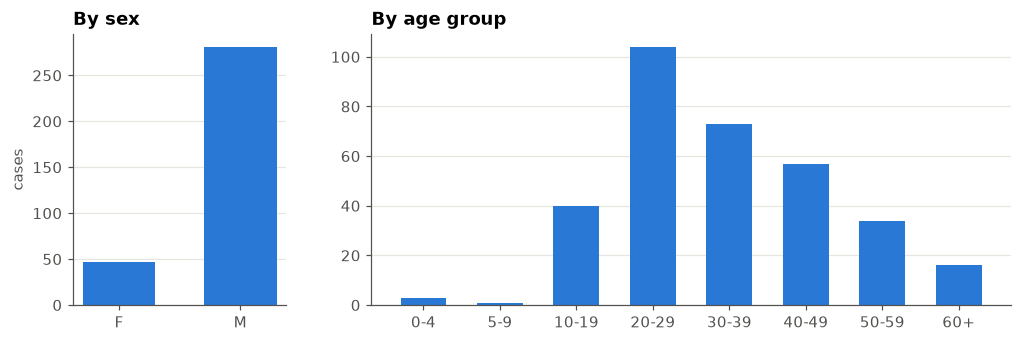

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 3]})
sex = z.groupby("sex").case_total.sum()
axes[0].bar(sex.index, sex.values, color=BLUE, width=0.6)
axes[0].set(title="By sex", ylabel="cases")
order = ["0-4", "5-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60+"]
age = z.groupby("age_group").case_total.sum().reindex(order, fill_value=0)
axes[1].bar(age.index, age.values, color=BLUE, width=0.6)
axes[1].set(title="By age group")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.show()

**Takeaway:** cases are mostly **men aged 20–49**, consistent with exposure through outdoor work
and wading in floodwater. That's the group prophylaxis and messaging should reach.

## 2. Barangay table

In [3]:
noah = pd.read_csv(RAW / "project_noah_hazards.csv").set_index("adm4_pcode")
pop = pd.read_csv(RAW / "worldpop_population.csv", parse_dates=["date"])
pop = pop[pop.date.dt.year.between(2013, 2020)].groupby("adm4_pcode").pop_count_total.mean()  # WorldPop ends 2020

b = barangays().query("city == @ZAMBOANGA").set_index("adm4_pcode")
b["cases"] = z.groupby("adm4_pcode").case_total.sum().reindex(b.index, fill_value=0)
b["pop"] = pop
b["hazard_pct"] = noah.pct_area_flood_hazard_25yr_med + noah.pct_area_flood_hazard_25yr_high
b["rate"] = b.cases / b["pop"] * 1e5 / 10  # per 100k people per year
print(f"{len(b)} barangays, {(b.cases > 0).sum()} with at least one case")
b[["adm4_en", "cases", "pop", "hazard_pct", "rate"]].sort_values("cases", ascending=False).head(10).round(1)

101 barangays, 60 with at least one case


,adm4_en,cases,pop,hazard_pct,rate
adm4_pcode,,,,,
PH097332094,Tumaga,41,33045.7,28.9,12.4
PH097332059,Pasonanca,28,45244.8,15.1,6.2
PH097332087,Tetuan,24,26265.7,9.6,9.1
PH097332092,Tugbungan,18,20777.8,32.0,8.7
PH097332002,Ayala,14,13645.4,0.0,10.3
PH097332072,San Roque,14,31112.1,17.9,4.5
PH097332031,Guiwan,14,11814.1,20.8,11.9
PH097332085,Talon-talon,10,35826.9,2.6,2.8
PH097332076,Santa Maria,10,33043.9,36.8,3.0


`hazard_pct` = share of the barangay's area in **medium or high** flood hazard for a
25-year rain (NOAH). `rate` = cases per 100,000 people per year.

## 3. Population drives raw counts

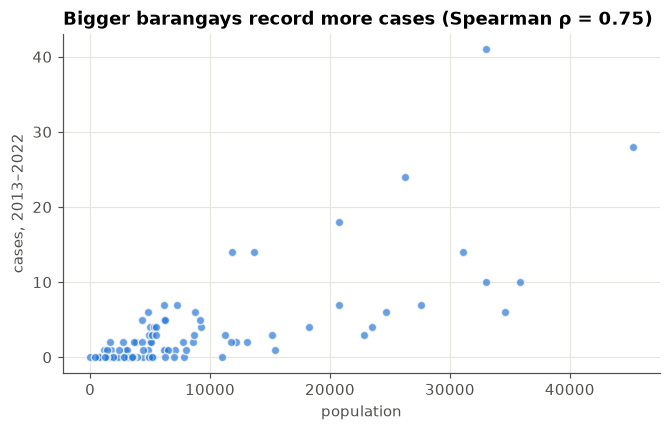

In [4]:
rho, _ = spearmanr(b["pop"], b.cases)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(b["pop"], b.cases, color=BLUE, s=30, alpha=0.7, edgecolor="white")
ax.set(title=f"Bigger barangays record more cases (Spearman ρ = {rho:.2f})",
       xlabel="population", ylabel="cases, 2013–2022")
plt.show()

**Takeaway:** population alone explains much of the raw count, so hazard has to be judged on
the **rate**, not the count.

## 4. Flood hazard vs case rate

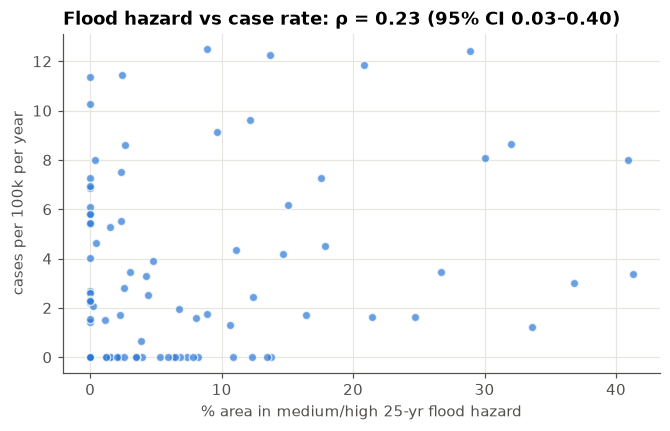

In [5]:
rho, p = spearmanr(b.hazard_pct, b.rate)
lo, hi = bootstrap_ci(b.hazard_pct, b.rate, lambda x, y: spearmanr(x, y)[0])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(b.hazard_pct, b.rate, color=BLUE, s=30, alpha=0.7, edgecolor="white")
ax.set(title=f"Flood hazard vs case rate: ρ = {rho:.2f} (95% CI {lo:.2f}–{hi:.2f})",
       xlabel="% area in medium/high 25-yr flood hazard", ylabel="cases per 100k per year")
plt.show()

In [6]:
b["hazard_group"] = pd.cut(b.hazard_pct, [-0.1, 0, 10, 100], labels=["none", "0–10%", ">10%"])
g = b.groupby("hazard_group", observed=True).agg(barangays=("cases", "size"), cases=("cases", "sum"), pop=("pop", "sum"))
g["rate_per_100k_yr"] = g.cases / g["pop"] * 1e5 / 10
g.round(1)

,barangays,cases,pop,rate_per_100k_yr
hazard_group,,,,
none,33,58,154839.5,3.7
0–10%,43,90,297421.8,3.0
>10%,25,180,363710.1,4.9


In [7]:
rows = []
for col in ["25yr_med", "25yr_high", "5yr_high", "100yr_high"]:
    r, p = spearmanr(noah[f"pct_area_flood_hazard_{col}"].reindex(b.index), b.rate)
    rows.append((col, round(r, 2), round(p, 3)))
pd.DataFrame(rows, columns=["hazard layer", "spearman ρ", "p"])

,hazard layer,spearman ρ,p
0,25yr_med,0.26,0.009
1,25yr_high,-0.00,0.990
2,5yr_high,-0.03,0.741
3,100yr_high,0.10,0.344


**Takeaways**
- Barangays with more flood-prone area have **somewhat higher case rates**: ρ ≈ 0.23,
  and the 95% CI barely clears zero.
- The signal comes from the **25-year medium** layer. "High" hazard alone shows nothing. The
  layer is a choice, and it should be stated, not tuned further on 101 barangays.
- This is **weak evidence** from one city with sparse counts (60 of 101 barangays ever had a
  case). In the app, the barangay ranking is presented as **estimated exposure**, not a
  prediction of cases, and community flood reports refine it.
- Recorded cases also depend on where people seek care (detection bias), which hazard maps
  can't capture.

## Summary

| Finding | Implication |
|---|---|
| Mostly men aged 20–49 | Target group for prophylaxis and messaging |
| Population drives counts | Rank on hazard × population; judge hazard on rates |
| Hazard vs rate ρ ≈ 0.23 (CI 0.03–0.40) | Weak but positive: label the ranking "estimated exposure" |